In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass, replace, asdict

pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})


@dataclass(frozen=True)
class Params:
    users0: float = 1000      # U0, utilisateurs de départ
    ad_spend: float = 5000    # € / mois
    cac: float = 50           # € / utilisateur payant
    churn: float = 0.10       # % mensuel
    referral: float = 0.05    # nouveaux users par user retenu / mois
    arpu: float = 10          # € / user / mois
    margin: float = 0.80      # marge brute


# Mêmes valeurs que la feuille "Inputs" (ad spend gardé constant pour isoler les autres leviers)
SCENARIOS = {
    "Base":        Params(),
    "Optimistic":  Params(cac=40, churn=0.05, referral=0.10),
    "Pessimistic": Params(cac=70, churn=0.12, referral=0.02),
    # Custom : à vous de jouer (ex. ad_spend=0 pour la question 3)
    "Custom":      Params(),
}

pd.DataFrame({k: asdict(v) for k, v in SCENARIOS.items()}).T

,users0,ad_spend,cac,churn,referral,arpu,margin
Base,"1,000.00","5,000.00",50.00,0.10,0.05,10.00,0.80
Optimistic,"1,000.00","5,000.00",40.00,0.05,0.10,10.00,0.80
Pessimistic,"1,000.00","5,000.00",70.00,0.12,0.02,10.00,0.80
Custom,"1,000.00","5,000.00",50.00,0.10,0.05,10.00,0.80


In [6]:
def simulate(p: Params, months: int = 12) -> pd.DataFrame:
    # Équivalent de la feuille 'Model' : détail mensuel.
    new_paid = p.ad_spend / p.cac if p.cac > 0 else 0.0
    rows = [dict(month=0, start=np.nan, churned=np.nan, retained=np.nan, paid_new=np.nan,
                 referrals=np.nan, end=p.users0, mom_growth=np.nan, revenue=np.nan,
                 gross_profit=np.nan, ad_spend=np.nan, cum_gp_minus_spend=0.0)]
    end, cum = p.users0, 0.0
    for m in range(1, months + 1):
        start = end
        churned = start * p.churn
        retained = start - churned
        referrals = retained * p.referral
        end = retained + new_paid + referrals
        revenue = end * p.arpu
        gp = revenue * p.margin
        cum += gp - p.ad_spend
        rows.append(dict(month=m, start=start, churned=churned, retained=retained,
                         paid_new=new_paid, referrals=referrals, end=end,
                         mom_growth=end / start - 1 if start > 0 else 0.0,
                         revenue=revenue, gross_profit=gp, ad_spend=p.ad_spend,
                         cum_gp_minus_spend=cum))
    return pd.DataFrame(rows).set_index("month")


def unit_economics(p: Params) -> dict:
    # Équivalent du bloc 'Unit economics' de la feuille 'Inputs'.
    factor = (1 - p.churn) * (1 + p.referral)
    ltv = p.arpu * p.margin / p.churn if p.churn > 0 else 0.0
    return {
        "New paid users / month": p.ad_spend / p.cac if p.cac > 0 else 0.0,
        "LTV (gross margin)": ltv,
        "LTV : CAC": ltv / p.cac if p.cac > 0 else 0.0,
        "CAC payback (months)": p.cac / (p.arpu * p.margin) if p.arpu * p.margin > 0 else 0.0,
        "Monthly growth factor (excl. ads)": factor,
        "Self-sustaining without ads?": "YES — the loop grows alone" if factor >= 1 else "NO — needs paid fuel",
    }


def users_path(p: Params, months: int = 12) -> np.ndarray:
    # Version légère : uniquement la trajectoire d'utilisateurs (M0..Mn).
    return simulate(p, months)["end"].to_numpy()

In [7]:
example = simulate(SCENARIOS["Base"]).loc[1, "end"]
print(f"Base, mois 1 : {example:,.0f} utilisateurs (attendu : 1 045)")
assert round(example) == 1045, "Le modèle ne reproduit pas la slide EXAMPLE"

Base, mois 1 : 1,045 utilisateurs (attendu : 1 045)


In [8]:
SELECTED = "Base"   # ← changez : Base / Optimistic / Pessimistic / Custom

model = simulate(SCENARIOS[SELECTED])
print(f"Scénario : {SELECTED}")
display(model.style.format({
    "start": "{:,.0f}", "churned": "{:,.0f}", "retained": "{:,.0f}", "paid_new": "{:,.0f}",
    "referrals": "{:,.0f}", "end": "{:,.0f}", "mom_growth": "{:.1%}",
    "revenue": "{:,.0f}", "gross_profit": "{:,.0f}", "ad_spend": "{:,.0f}",
    "cum_gp_minus_spend": "{:,.0f}"}, na_rep="—"))

totals = model[["paid_new", "referrals", "revenue", "gross_profit", "ad_spend"]].sum()
print("\nTotaux sur 12 mois :")
print(totals.map("{:,.0f}".format).to_string())

print("\nUnit economics :")
for k, v in unit_economics(SCENARIOS[SELECTED]).items():
    print(f"  {k:<36} {v:,.2f}" if isinstance(v, float) else f"  {k:<36} {v}")

Scénario : Base


,start,churned,retained,paid_new,referrals,end,mom_growth,revenue,gross_profit,ad_spend,cum_gp_minus_spend
month,,,,,,,,,,,
0,—,—,—,—,—,"1,000",—,—,—,—,0
1,"1,000",100,900,100,45,"1,045",4.5%,"10,450","8,360","5,000","3,360"
2,"1,045",104,940,100,47,"1,088",4.1%,"10,875","8,700","5,000","7,060"
3,"1,088",109,979,100,49,"1,128",3.7%,"11,277","9,022","5,000","11,082"
4,"1,128",113,"1,015",100,51,"1,166",3.4%,"11,657","9,325","5,000","15,407"
5,"1,166",117,"1,049",100,52,"1,202",3.1%,"12,016","9,613","5,000","20,020"
6,"1,202",120,"1,081",100,54,"1,235",2.8%,"12,355","9,884","5,000","24,904"
7,"1,235",124,"1,112",100,56,"1,268",2.6%,"12,675","10,140","5,000","30,044"
8,"1,268",127,"1,141",100,57,"1,298",2.4%,"12,978","10,383","5,000","35,427"



Totaux sur 12 mois :
paid_new          1,200
referrals           652
revenue         148,905
gross_profit    119,124
ad_spend         60,000

Unit economics :
  New paid users / month               100.00
  LTV (gross margin)                   80.00
  LTV : CAC                            1.60
  CAC payback (months)                 6.25
  Monthly growth factor (excl. ads)    0.95
  Self-sustaining without ads?         NO — needs paid fuel


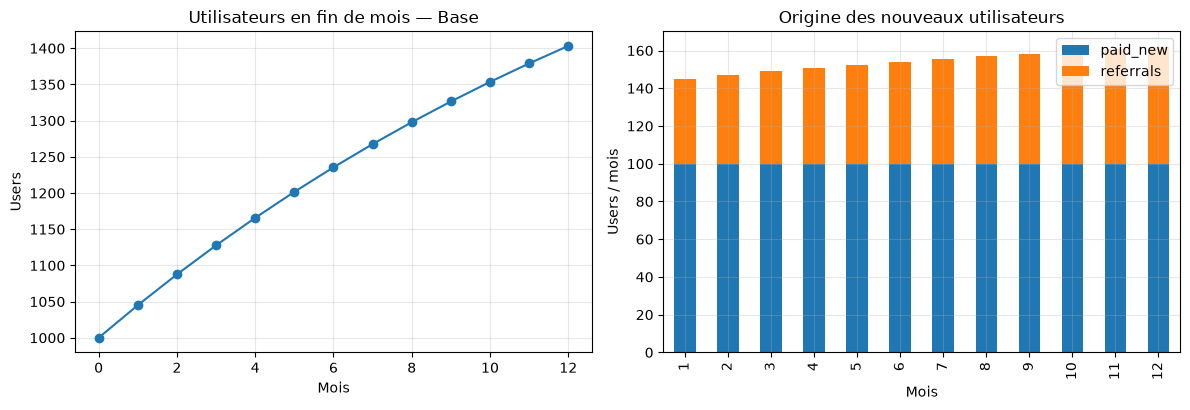

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
model["end"].plot(ax=ax[0], marker="o")
ax[0].set(title=f"Utilisateurs en fin de mois — {SELECTED}", xlabel="Mois", ylabel="Users")

model[["paid_new", "referrals"]].iloc[1:].plot.bar(stacked=True, ax=ax[1])
ax[1].set(title="Origine des nouveaux utilisateurs", xlabel="Mois", ylabel="Users / mois")
plt.tight_layout(); plt.show()

In [10]:
def scenario_table(scens: dict, months: int = 12, ref: str = "Base") -> pd.DataFrame:
    paths = {name: users_path(p, months) for name, p in scens.items()}
    out = pd.DataFrame({
        "U0": {n: p.users0 for n, p in scens.items()},
        "Spend": {n: p.ad_spend for n, p in scens.items()},
        "CAC": {n: p.cac for n, p in scens.items()},
        "Churn": {n: p.churn for n, p in scens.items()},
        "Referral": {n: p.referral for n, p in scens.items()},
        "ARPU": {n: p.arpu for n, p in scens.items()},
        "Margin": {n: p.margin for n, p in scens.items()},
        "Users M12": {n: paths[n][-1] for n in scens},
        "MRR M12 (€)": {n: paths[n][-1] * p.arpu for n, p in scens.items()},
        "LTV:CAC": {n: unit_economics(p)["LTV : CAC"] for n, p in scens.items()},
    })
    out["Users M12 vs Base"] = out["Users M12"] / out.loc[ref, "Users M12"] - 1
    return out


tbl = scenario_table(SCENARIOS)
display(tbl.style.format({
    "U0": "{:,.0f}", "Spend": "{:,.0f}", "CAC": "{:,.0f}", "Churn": "{:.0%}", "Referral": "{:.0%}",
    "ARPU": "{:,.0f}", "Margin": "{:.0%}", "Users M12": "{:,.0f}", "MRR M12 (€)": "{:,.0f}",
    "LTV:CAC": "{:.2f}", "Users M12 vs Base": "{:+.1%}"}))

,U0,Spend,CAC,Churn,Referral,ARPU,Margin,Users M12,MRR M12 (€),LTV:CAC,Users M12 vs Base
Base,"1,000","5,000",50,10%,5%,10,80%,"1,403","14,032",1.60,+0.0%
Optimistic,"1,000","5,000",40,5%,10%,10,80%,"3,629","36,289",4.00,+158.6%
Pessimistic,"1,000","5,000",70,12%,2%,10,80%,780,"7,803",0.95,-44.4%
Custom,"1,000","5,000",50,10%,5%,10,80%,"1,403","14,032",1.60,+0.0%


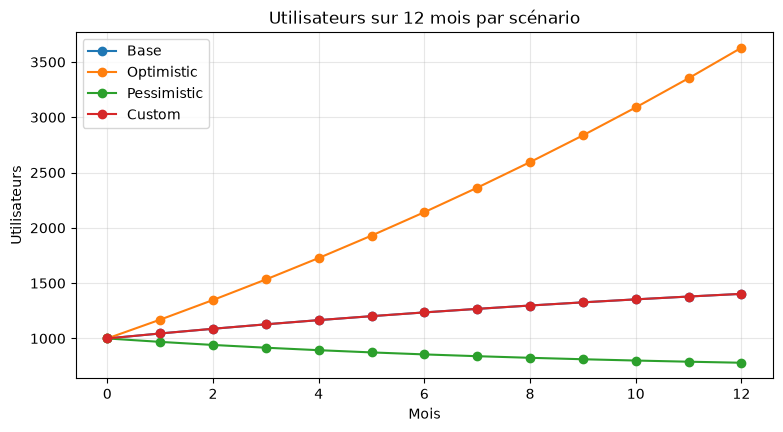

In [11]:
fig, ax = plt.subplots()
for name, p in SCENARIOS.items():
    ax.plot(range(13), users_path(p), marker="o", label=name)
ax.set(title="Utilisateurs sur 12 mois par scénario", xlabel="Mois", ylabel="Utilisateurs")
ax.legend(); plt.show()

,CAC,Churn,Referral,ARPU,Users M12,MRR M12 (€),LTV:CAC,Users M12 vs Base
Base,50,10.0%,5.0%,10.0,"1,403","14,032",1.60,+0.0%
CAC −20 %,40,10.0%,5.0%,10.0,"1,627","16,272",2.00,+16.0%
Churn −20 %,50,8.0%,5.0%,10.0,"1,659","16,595",2.00,+18.3%
ARPU +20 %,50,10.0%,5.0%,12.0,"1,403","16,838",1.92,+0.0%
Referral +20 %,50,10.0%,6.0%,10.0,"1,507","15,068",1.60,+7.4%


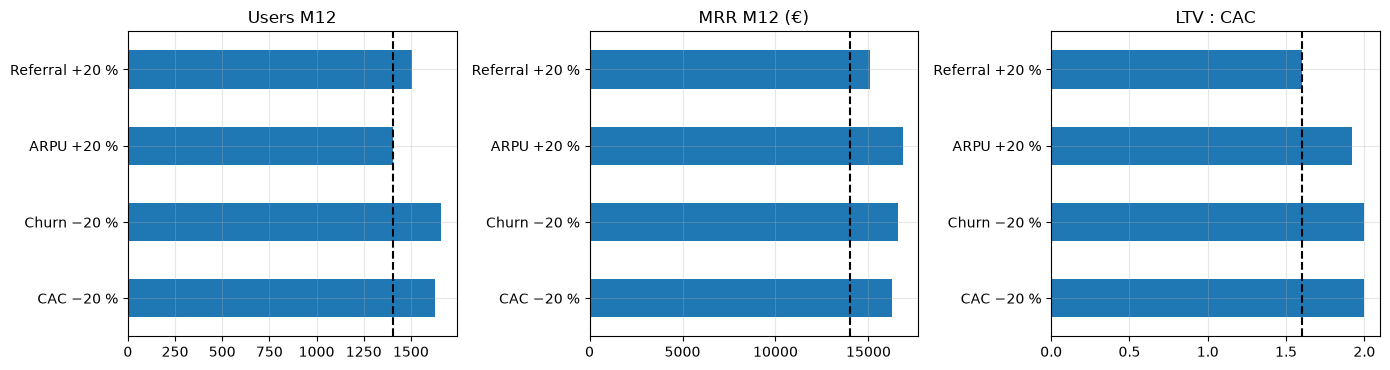

Meilleur levier sur Users M12 : Churn −20 %
Meilleur levier sur LTV:CAC   : CAC −20 %


In [12]:
base = SCENARIOS["Base"]
LEVERS = {
    "Base":              base,
    "CAC −20 %":         replace(base, cac=base.cac * 0.8),
    "Churn −20 %":       replace(base, churn=base.churn * 0.8),
    "ARPU +20 %":        replace(base, arpu=base.arpu * 1.2),
    "Referral +20 %":    replace(base, referral=base.referral * 1.2),
}
sens = scenario_table(LEVERS)
display(sens[["CAC", "Churn", "Referral", "ARPU", "Users M12", "MRR M12 (€)", "LTV:CAC", "Users M12 vs Base"]]
        .style.format({"CAC": "{:.0f}", "Churn": "{:.1%}", "Referral": "{:.1%}", "ARPU": "{:.1f}",
                       "Users M12": "{:,.0f}", "MRR M12 (€)": "{:,.0f}", "LTV:CAC": "{:.2f}",
                       "Users M12 vs Base": "{:+.1%}"}))

gain = sens.drop("Base")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
gain["Users M12"].plot.barh(ax=ax[0], title="Users M12"); ax[0].axvline(sens.loc["Base", "Users M12"], color="k", ls="--")
gain["MRR M12 (€)"].plot.barh(ax=ax[1], title="MRR M12 (€)"); ax[1].axvline(sens.loc["Base", "MRR M12 (€)"], color="k", ls="--")
gain["LTV:CAC"].plot.barh(ax=ax[2], title="LTV : CAC"); ax[2].axvline(sens.loc["Base", "LTV:CAC"], color="k", ls="--")
plt.tight_layout(); plt.show()

print("Meilleur levier sur Users M12 :", gain["Users M12"].idxmax())
print("Meilleur levier sur LTV:CAC   :", gain["LTV:CAC"].idxmax())

In [13]:
def r_min(churn: float) -> float:
    # Referral minimal pour stopper la décroissance sans pub.
    return churn / (1 - churn)


def steady_state(p: Params) -> float:
    f = (1 - p.churn) * (1 + p.referral)
    new = p.ad_spend / p.cac if p.cac > 0 else 0.0
    return new / (1 - f) if f < 1 else np.inf


rows = []
for name, p in SCENARIOS.items():
    f = (1 - p.churn) * (1 + p.referral)
    rows.append({"Scénario": name, "Churn": p.churn, "Referral": p.referral,
                 "Referral min (sans pub)": r_min(p.churn), "Facteur (1−c)(1+r)": f,
                 "Auto-suffisant ?": "OUI" if f >= 1 else "NON",
                 "Users état stationnaire (avec pub)": steady_state(p)})
display(pd.DataFrame(rows).set_index("Scénario").style.format({
    "Churn": "{:.0%}", "Referral": "{:.0%}", "Referral min (sans pub)": "{:.2%}",
    "Facteur (1−c)(1+r)": "{:.3f}", "Users état stationnaire (avec pub)": "{:,.0f}"}))

print(f"\nQuestion 3 — Custom avec ad_spend = 0, churn = {SCENARIOS['Custom'].churn:.0%} → "
      f"referral minimum = {r_min(SCENARIOS['Custom'].churn):.2%}")

,Churn,Referral,Referral min (sans pub),Facteur (1−c)(1+r),Auto-suffisant ?,Users état stationnaire (avec pub)
Scénario,,,,,,
Base,10%,5%,11.11%,0.945,NON,"1,818"
Optimistic,5%,10%,5.26%,1.045,OUI,inf
Pessimistic,12%,2%,13.64%,0.898,NON,698
Custom,10%,5%,11.11%,0.945,NON,"1,818"



Question 3 — Custom avec ad_spend = 0, churn = 10% → referral minimum = 11.11%


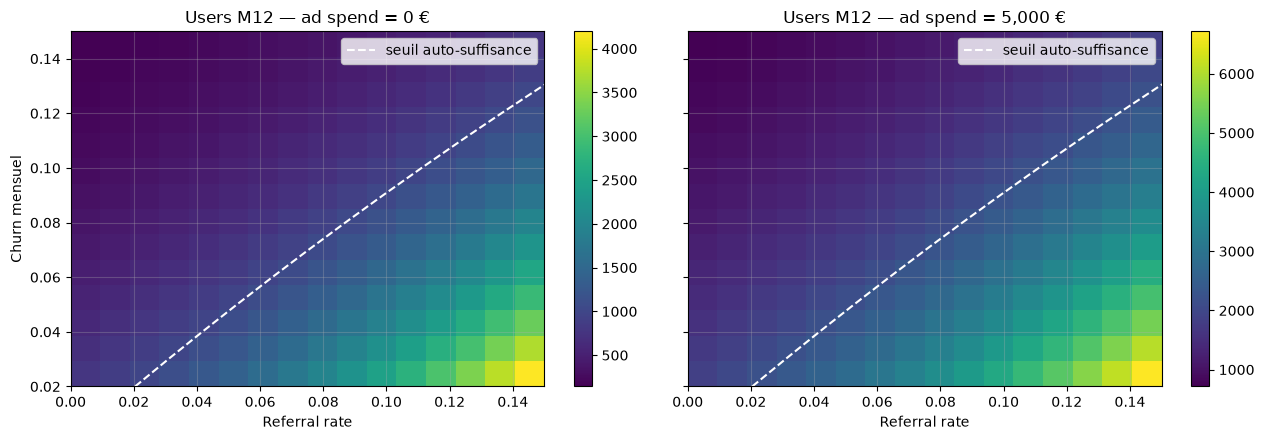

In [14]:
# Heatmap : users au mois 12 selon churn x referral (sans pub puis avec pub)
churns = np.linspace(0.02, 0.15, 14)
refs = np.linspace(0.0, 0.15, 16)

def grid(spend):
    return np.array([[users_path(replace(base, churn=c, referral=r, ad_spend=spend))[-1]
                      for r in refs] for c in churns])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, spend in zip(axes, [0, base.ad_spend]):
    g = grid(spend)
    im = ax.imshow(g, origin="lower", aspect="auto", cmap="viridis",
                   extent=[refs[0], refs[-1], churns[0], churns[-1]])
    ax.plot(r_min(churns), churns, "w--", label="seuil auto-suffisance")
    ax.set(title=f"Users M12 — ad spend = {spend:,.0f} €", xlabel="Referral rate", xlim=(refs[0], refs[-1]))
    ax.legend(loc="upper right"); fig.colorbar(im, ax=ax)
axes[0].set_ylabel("Churn mensuel")
plt.tight_layout(); plt.show()

In [ ]:
@dataclass(frozen=True)
class ExerciseParams:
    mau0: float = 5000
    organic: float = 1000
    churn: float = 0.10
    budget: float = 10000
    churn_after_product: float = 0.08   # effectif dès le mois 2
    cac: float = 50                     # budget étalé sur les mois 1-3


def exercise(e: ExerciseParams, months: int = 6) -> pd.DataFrame:
    extra = e.budget / e.cac / 3 if e.cac > 0 else 0.0
    sq = prod = ads = e.mau0
    rows = [dict(month=0, status_quo=sq, product=prod, ads=ads)]
    for m in range(1, months + 1):
        sq   = sq * (1 - e.churn) + e.organic
        prod = prod * (1 - (e.churn_after_product if m >= 2 else e.churn)) + e.organic
        ads  = ads * (1 - e.churn) + e.organic + (extra if m <= 3 else 0.0)
        rows.append(dict(month=m, status_quo=sq, product=prod, ads=ads))
    return pd.DataFrame(rows).set_index("month")


def verdict(e: ExerciseParams, month: int = 6):
    df = exercise(e, max(month, 6))
    g1 = df.loc[month, "product"] - df.loc[month, "status_quo"]
    g2 = df.loc[month, "ads"] - df.loc[month, "status_quo"]
    win = "Option 1 : product" if g1 > g2 else "Option 2 : ads" if g2 > g1 else "Tie"
    return g1, g2, win


E = ExerciseParams()
ex = exercise(E)
display(ex.style.format("{:,.0f}"))
g1, g2, win = verdict(E)
print(f"Gain MAU M6 vs status quo — produit : {g1:+,.0f} | ads : {g2:+,.0f} → gagnant : {win}")

ex.plot(marker="o", title="MAU : status quo vs produit vs ads"); plt.ylabel("MAU"); plt.show()